
💖 Recorrido para: 'Luz' (Corazones: 1, Palabras: 1)
🛤️ Ruta exacta de nodos: contar_corazones ➔ pradera_ponis ➔ guardar_suenos


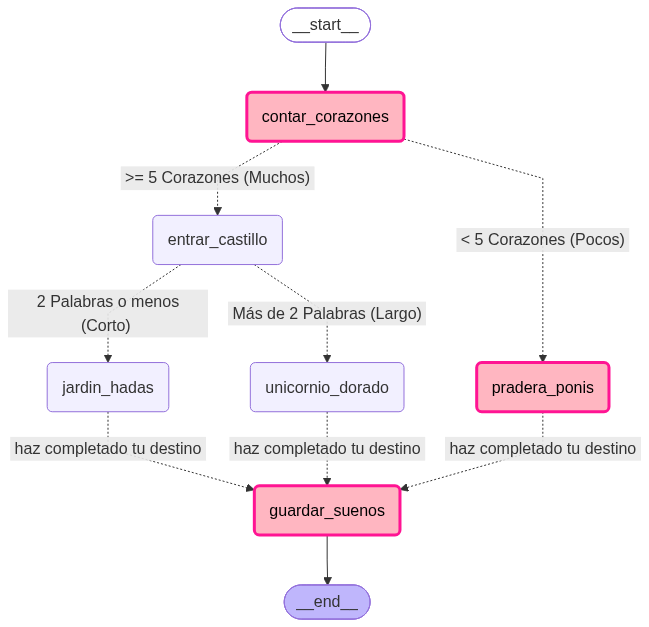

📤 Resultado del cuento: {'protagonista': 'Luz', 'historia_magica': '🦄✨ Luz cabalga con ponis de colores 12345 ✨🦄', 'detalles': {'corazones': 1, 'palabras': 1}, 'lugar': 'Pradera de Ponis y Estrellas', 'mensaje_final': 'haz completado tu destino'}

💖 Recorrido para: 'Princesa Sofía' (Corazones: 6, Palabras: 2)
🛤️ Ruta exacta de nodos: contar_corazones ➔ entrar_castillo ➔ jardin_hadas ➔ guardar_suenos


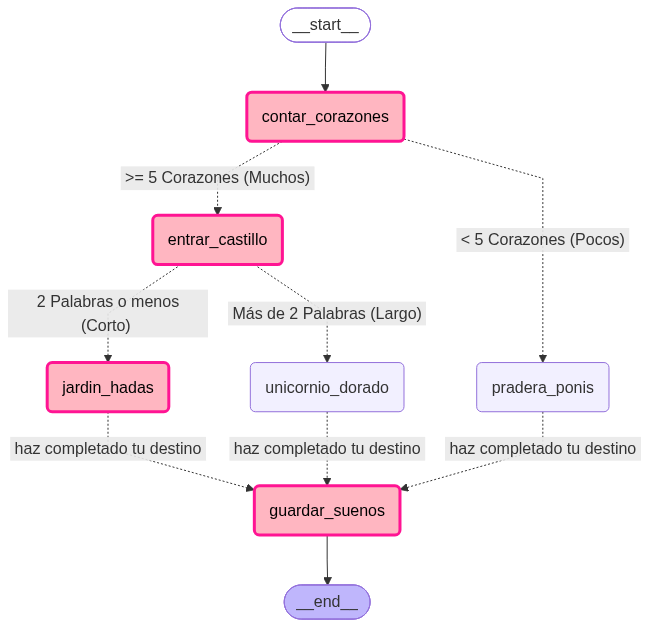

📤 Resultado del cuento: {'protagonista': 'Princesa Sofía', 'historia_magica': '🦋 🌸 *la princesa princesa sofía baila con hadas y flores* 🌸 🦋', 'detalles': {'corazones': 6, 'palabras': 2}, 'lugar': 'Jardín de Hadas y Flores (Susurro de Mariposa)', 'mensaje_final': 'haz completado tu destino'}

💖 Recorrido para: 'Valentina y su unicornio mágico' (Corazones: 13, Palabras: 5)
🛤️ Ruta exacta de nodos: contar_corazones ➔ entrar_castillo ➔ unicornio_dorado ➔ guardar_suenos


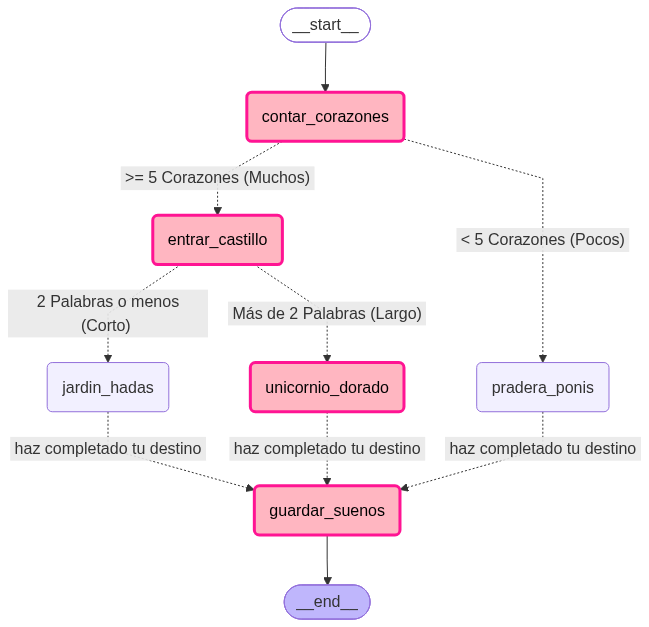

📤 Resultado del cuento: {'protagonista': 'Valentina y su unicornio mágico', 'historia_magica': '👑 🦄 ✨ ¡VALENTINA Y SU UNICORNIO MÁGICO ES LA REINA DEL UNICORNIO DORADO! ✨ 🦄 👑', 'detalles': {'corazones': 13, 'palabras': 5}, 'lugar': 'Reino del Unicornio Dorado (Corona Brillante)', 'mensaje_final': 'haz completado tu destino'}


In [25]:
from typing import TypedDict, Dict, Any
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables.graph_mermaid import draw_mermaid_png
from IPython.display import Image, display

# 1. Definir el Estado
class GraphState(TypedDict):
    nombre_nina: str
    cuento_magico: str
    magia_corazones: int
    palabras_deseo: int
    reino_visitado: str
    mensaje_destino: str
    libro_de_cuentos: Dict[str, Any]

# 2. Nodos del Cuento Mágico
def nodo_contar_corazones_magicos(state: GraphState) -> Dict[str, Any]:
    nombre = state["nombre_nina"]
    vocales = "aeiouáéíóúAEIOUÁÉÍÓÚ"
    corazones = sum(1 for char in nombre if char in vocales)
    palabras = len(nombre.split())
    return {"magia_corazones": corazones, "palabras_deseo": palabras}

def nodo_entrar_al_castillo_de_la_princesa(state: GraphState) -> Dict[str, Any]:
    return {"reino_visitado": "Entró al Castillo de la Princesa"}

def nodo_pradera_con_destino(state: GraphState) -> Dict[str, Any]:
    return {
        "cuento_magico": f"🦄✨ {state['nombre_nina']} cabalga con ponis de colores 12345 ✨🦄",
        "reino_visitado": "Pradera de Ponis y Estrellas",
        "mensaje_destino": "haz completado tu destino"
    }

def nodo_reino_con_destino(state: GraphState) -> Dict[str, Any]:
    return {
        "cuento_magico": f"👑 🦄 ✨ ¡{state['nombre_nina'].upper()} ES LA REINA DEL UNICORNIO DORADO! ✨ 🦄 👑",
        "reino_visitado": "Reino del Unicornio Dorado (Corona Brillante)",
        "mensaje_destino": "haz completado tu destino"
    }

def nodo_jardin_con_destino(state: GraphState) -> Dict[str, Any]:
    return {
        "cuento_magico": f"🦋 🌸 *la princesa {state['nombre_nina'].lower()} baila con hadas y flores* 🌸 🦋",
        "reino_visitado": "Jardín de Hadas y Flores (Susurro de Mariposa)",
        "mensaje_destino": "haz completado tu destino"
    }

def nodo_guardar_en_el_libro_de_suenos(state: GraphState) -> Dict[str, Any]:
    libro_de_cuentos = {
        "protagonista": state["nombre_nina"],
        "historia_magica": state["cuento_magico"],
        "detalles": {"corazones": state["magia_corazones"], "palabras": state["palabras_deseo"]},
        "lugar": state["reino_visitado"],
        "mensaje_final": state.get("mensaje_destino", "")
    }
    return {"libro_de_cuentos": libro_de_cuentos}

# 3. Enrutadores condicionales
def enrutar_por_magia_de_corazones(state: GraphState) -> str:
    if state["magia_corazones"] < 5:
        return "< 5 Corazones (Pocos)"
    else:
        return ">= 5 Corazones (Muchos)"

def enrutar_por_tamano_del_deseo(state: GraphState) -> str:
    if state["palabras_deseo"] > 2:
        return "Más de 2 Palabras (Largo)"
    else:
        return "2 Palabras o menos (Corto)"

def ruta_hacia_guardar(state: GraphState) -> str:
    return "haz completado tu destino"

# 4. Construcción del Grafo
workflow = StateGraph(GraphState)

workflow.add_node("contar_corazones", nodo_contar_corazones_magicos)
workflow.add_node("pradera_ponis", nodo_pradera_con_destino)
workflow.add_node("entrar_castillo", nodo_entrar_al_castillo_de_la_princesa)
workflow.add_node("unicornio_dorado", nodo_reino_con_destino)
workflow.add_node("jardin_hadas", nodo_jardin_con_destino)
workflow.add_node("guardar_suenos", nodo_guardar_en_el_libro_de_suenos)

workflow.add_edge(START, "contar_corazones")

workflow.add_conditional_edges(
    "contar_corazones",
    enrutar_por_magia_de_corazones,
    {
        "< 5 Corazones (Pocos)": "pradera_ponis",
        ">= 5 Corazones (Muchos)": "entrar_castillo"
    }
)

workflow.add_conditional_edges(
    "entrar_castillo",
    enrutar_por_tamano_del_deseo,
    {
        "Más de 2 Palabras (Largo)": "unicornio_dorado",
        "2 Palabras o menos (Corto)": "jardin_hadas"
    }
)

workflow.add_conditional_edges(
    "pradera_ponis",
    ruta_hacia_guardar,
    {"haz completado tu destino": "guardar_suenos"}
)
workflow.add_conditional_edges(
    "unicornio_dorado",
    ruta_hacia_guardar,
    {"haz completado tu destino": "guardar_suenos"}
)
workflow.add_conditional_edges(
    "jardin_hadas",
    ruta_hacia_guardar,
    {"haz completado tu destino": "guardar_suenos"}
)

workflow.add_edge("guardar_suenos", END)

app = workflow.compile()

# ==========================================
# 5. FUNCIÓN SEGURA PARA PINTAR EL RECORRIDO
# ==========================================
def ejecutar_y_pintar_recorrido(nombre_frase):
    vowels = "aeiouáéíóúAEIOUÁÉÍÓÚ"
    corazones = sum(1 for char in nombre_frase if char in vowels)
    palabras = len(nombre_frase.split())
    
    nodos_recorridos = ["contar_corazones"]
    if corazones < 5:
        nodos_recorridos.append("pradera_ponis")
    else:
        nodos_recorridos.append("entrar_castillo")
        if palabras > 2:
            nodos_recorridos.append("unicornio_dorado")
        else:
            nodos_recorridos.append("jardin_hadas")
    nodos_recorridos.append("guardar_suenos")
    
    print(f"\n💖 Recorrido para: '{nombre_frase}' (Corazones: {corazones}, Palabras: {palabras})")
    print(f"🛤️ Ruta exacta de nodos: {' ➔ '.join(nodos_recorridos)}")
    
    # Intentar renderizar la imagen con alta tolerancia a fallos de red
    try:
        mermaid_code = app.get_graph().draw_mermaid()
        estilos_rosados = "\n"
        for nodo in nodos_recorridos:
            estilos_rosados += f"style {nodo} fill:#ffb6c1,stroke:#ff1493,stroke-width:3px,color:#000000;\n"
            
        mermaid_code_modificado = mermaid_code + estilos_rosados
        
        # Mayor tiempo de espera y múltiples reintentos configurados
        img_bytes = draw_mermaid_png(
            mermaid_code_modificado, 
            max_retries=5, 
            retry_delay=2.0
        )
        display(Image(img_bytes))
    except Exception as e:
        print(("⚠️ El servidor de imágenes de Mermaid tardó en responder, "
               "pero la lógica del grafo se ejecutó con éxito a continuación:"))
    
    # Ejecutar la app con LangGraph
    estado_inicial = {
        "nombre_nina": nombre_frase, 
        "cuento_magico": "", 
        "magia_corazones": 0, 
        "palabras_deseo": 0, 
        "reino_visitado": "", 
        "mensaje_destino": "",
        "libro_de_cuentos": {}
    }
    resultado = app.invoke(estado_inicial)
    print("📤 Resultado del cuento:", resultado["libro_de_cuentos"])
    print("=" * 60)

# ==========================================
# 6. PRUEBAS DINÁMICAS
# ==========================================
ejecutar_y_pintar_recorrido("Luz")
ejecutar_y_pintar_recorrido("Princesa Sofía")
ejecutar_y_pintar_recorrido("Valentina y su unicornio mágico")


💖 Recorrido iluminado para: 'Luz' (Corazones: 1, Palabras: 1)
🛤️ Ruta de nodos: contar_corazones ➔ pradera_ponis ➔ guardar_suenos


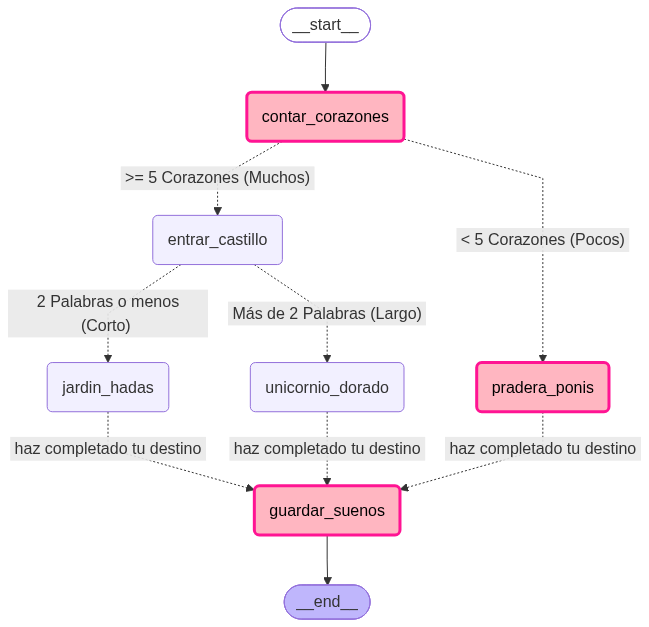

📤 Resultado: {'protagonista': 'Luz', 'historia_magica': '🦄✨ Luz cabalga con ponis de colores 12345 ✨🦄', 'detalles': {'corazones': 1, 'palabras': 1}, 'lugar': 'Pradera de Ponis y Estrellas', 'mensaje_final': 'haz completado tu destino'}

💖 Recorrido iluminado para: 'Princesa Sofía' (Corazones: 6, Palabras: 2)
🛤️ Ruta de nodos: contar_corazones ➔ entrar_castillo ➔ jardin_hadas ➔ guardar_suenos


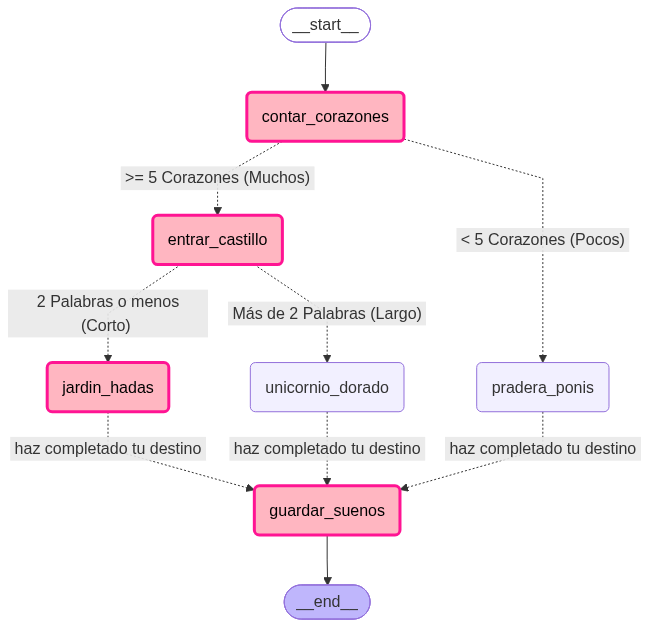

📤 Resultado: {'protagonista': 'Princesa Sofía', 'historia_magica': '🦋 🌸 *la princesa princesa sofía baila con hadas y flores* 🌸 🦋', 'detalles': {'corazones': 6, 'palabras': 2}, 'lugar': 'Jardín de Hadas y Flores (Susurro de Mariposa)', 'mensaje_final': 'haz completado tu destino'}

💖 Recorrido iluminado para: 'Valentina y su unicornio mágico' (Corazones: 13, Palabras: 5)
🛤️ Ruta de nodos: contar_corazones ➔ entrar_castillo ➔ unicornio_dorado ➔ guardar_suenos


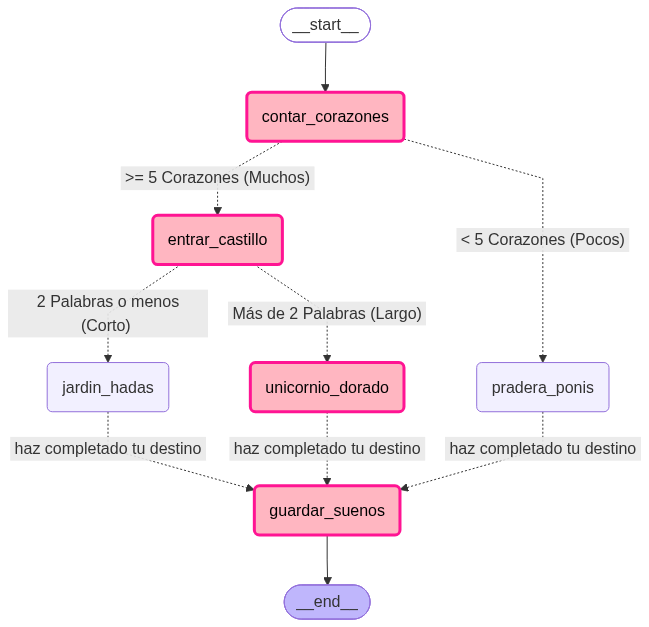

📤 Resultado: {'protagonista': 'Valentina y su unicornio mágico', 'historia_magica': '👑 🦄 ✨ ¡VALENTINA Y SU UNICORNIO MÁGICO ES LA REINA DEL UNICORNIO DORADO! ✨ 🦄 👑', 'detalles': {'corazones': 13, 'palabras': 5}, 'lugar': 'Reino del Unicornio Dorado (Corona Brillante)', 'mensaje_final': 'haz completado tu destino'}


In [31]:
from typing import TypedDict, Dict, Any, Callable
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables.graph_mermaid import draw_mermaid_png
from IPython.display import Image, display

# ==========================================
# 1. DEFINICIÓN DEL ESTADO
# ==========================================
class GraphState(TypedDict):
    nombre_nina: str
    cuento_magico: str
    magia_corazones: int
    palabras_deseo: int
    reino_visitado: str
    mensaje_destino: str
    libro_de_cuentos: Dict[str, Any]

# ==========================================
# 2. FUNCIONES AUXILIARES GENÉRICAS (HELPERS)
# ==========================================
def create_state_graph(state_schema: type) -> StateGraph:
    """Inicializa y retorna el constructor genérico del StateGraph."""
    return StateGraph(state_schema)

def add_node(workflow_graph: StateGraph, node_key: str, action_function: Callable) -> StateGraph:
    """Añade un nodo al grafo usando los parámetros estándar."""
    workflow_graph.add_node(node=node_key, action=action_function)
    return workflow_graph

def add_conditional_edges(
    workflow_graph: StateGraph, 
    source_node_key: str, 
    routing_function: Callable, 
    path_mapping_dict: Dict[str, str]
) -> StateGraph:
    """Añade aristas condicionales usando los parámetros estándar."""
    workflow_graph.add_conditional_edges(
        source=source_node_key, 
        path=routing_function, 
        path_map=path_mapping_dict
    )
    return workflow_graph

def add_edge(workflow_graph: StateGraph, source_node_key: str, target_node_key: str, arrow_label_key: str = None) -> StateGraph:
    """Función genérica para añadir aristas: directas (si no hay etiqueta) o con texto en la flecha."""
    if arrow_label_key:
        def enrutador_estatico(state: GraphState) -> str:
            return arrow_label_key
            
        workflow_graph.add_conditional_edges(
            source=source_node_key,
            path=enrutador_estatico,
            path_map={arrow_label_key: target_node_key}
        )
    else:
        workflow_graph.add_edge(source_node_key, target_node_key)
    return workflow_graph

# ==========================================
# 3. FUNCIONES DE ENRUTAMIENTO (ROUTERS)
# ==========================================
def enrutar_por_magia_de_corazones(state: GraphState) -> str:
    """Función de decisión para bifurcar según la cantidad de corazones (vocales)."""
    return "< 5 Corazones (Pocos)" if state["magia_corazones"] < 5 else ">= 5 Corazones (Muchos)"

def enrutar_por_tamano_del_deseo(state: GraphState) -> str:
    """Función de decisión para bifurcar según el tamaño del deseo (palabras)."""
    return "Más de 2 Palabras (Largo)" if state["palabras_deseo"] > 2 else "2 Palabras o menos (Corto)"

# ==========================================
# 4. NODOS DEL CUENTO MÁGICO
# ==========================================
def nodo_contar_corazones_magicos(state: GraphState) -> Dict[str, Any]:
    nombre = state["nombre_nina"]
    vocales = "aeiouáéíóúAEIOUÁÉÍÓÚ"
    corazones = sum(1 for char in nombre if char in vocales)
    palabras = len(nombre.split())
    return {"magia_corazones": corazones, "palabras_deseo": palabras}

def nodo_entrar_al_castillo_de_la_princesa(state: GraphState) -> Dict[str, Any]:
    return {"reino_visitado": "Entró al Castillo de la Princesa"}

def nodo_pradera_con_destino(state: GraphState) -> Dict[str, Any]:
    return {
        "cuento_magico": f"🦄✨ {state['nombre_nina']} cabalga con ponis de colores 12345 ✨🦄",
        "reino_visitado": "Pradera de Ponis y Estrellas",
        "mensaje_destino": "haz completado tu destino"
    }

def nodo_reino_con_destino(state: GraphState) -> Dict[str, Any]:
    return {
        "cuento_magico": f"👑 🦄 ✨ ¡{state['nombre_nina'].upper()} ES LA REINA DEL UNICORNIO DORADO! ✨ 🦄 👑",
        "reino_visitado": "Reino del Unicornio Dorado (Corona Brillante)",
        "mensaje_destino": "haz completado tu destino"
    }

def nodo_jardin_con_destino(state: GraphState) -> Dict[str, Any]:
    return {
        "cuento_magico": f"🦋 🌸 *la princesa {state['nombre_nina'].lower()} baila con hadas y flores* 🌸 🦋",
        "reino_visitado": "Jardín de Hadas y Flores (Susurro de Mariposa)",
        "mensaje_destino": "haz completado tu destino"
    }

def nodo_guardar_en_el_libro_de_suenos(state: GraphState) -> Dict[str, Any]:
    libro_de_cuentos = {
        "protagonista": state["nombre_nina"],
        "historia_magica": state["cuento_magico"],
        "detalles": {"corazones": state["magia_corazones"], "palabras": state["palabras_deseo"]},
        "lugar": state["reino_visitado"],
        "mensaje_final": state.get("mensaje_destino", "")
    }
    return {"libro_de_cuentos": libro_de_cuentos}

# ==========================================
# 5. ENSAMBLAJE DEL GRAFO
# ==========================================
workflow = create_state_graph(state_schema=GraphState)

# Adición de nodos
add_node(workflow_graph=workflow, node_key="contar_corazones", action_function=nodo_contar_corazones_magicos)
add_node(workflow_graph=workflow, node_key="pradera_ponis", action_function=nodo_pradera_con_destino)
add_node(workflow_graph=workflow, node_key="entrar_castillo", action_function=nodo_entrar_al_castillo_de_la_princesa)
add_node(workflow_graph=workflow, node_key="unicornio_dorado", action_function=nodo_reino_con_destino)
add_node(workflow_graph=workflow, node_key="jardin_hadas", action_function=nodo_jardin_con_destino)
add_node(workflow_graph=workflow, node_key="guardar_suenos", action_function=nodo_guardar_en_el_libro_de_suenos)

# Conexión inicial de entrada (START) usando add_edge
add_edge(workflow_graph=workflow, source_node_key=START, target_node_key="contar_corazones")

# Primera bifurcación usando los routers de la sección 3
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="contar_corazones",
    routing_function=enrutar_por_magia_de_corazones,
    path_mapping_dict={
        "< 5 Corazones (Pocos)": "pradera_ponis",
        ">= 5 Corazones (Muchos)": "entrar_castillo"
    }
)

# Segunda bifurcación anidada usando los routers de la sección 3
add_conditional_edges(
    workflow_graph=workflow,
    source_node_key="entrar_castillo",
    routing_function=enrutar_por_tamano_del_deseo,
    path_mapping_dict={
        "Más de 2 Palabras (Largo)": "unicornio_dorado",
        "2 Palabras o menos (Corto)": "jardin_hadas"
    }
)

# Conexiones finales horizontales usando add_edge
add_edge(workflow_graph=workflow, source_node_key="pradera_ponis", target_node_key="guardar_suenos", arrow_label_key="haz completado tu destino")
add_edge(workflow_graph=workflow, source_node_key="unicornio_dorado", target_node_key="guardar_suenos", arrow_label_key="haz completado tu destino")
add_edge(workflow_graph=workflow, source_node_key="jardin_hadas", target_node_key="guardar_suenos", arrow_label_key="haz completado tu destino")

# Conexión de salida (END) usando add_edge
add_edge(workflow_graph=workflow, source_node_key="guardar_suenos", target_node_key=END)

# Compilación final del grafo ejecutable
app = workflow.compile()

# ==========================================
# 6. EJECUCIÓN Y VISUALIZACIÓN ILUMINADA EN ROSADO
# ==========================================
def ejecutar_y_pintar_recorrido(nombre_frase: str):
    vowels = "aeiouáéíóúAEIOUÁÉÍÓÚ"
    corazones = sum(1 for char in nombre_frase if char in vowels)
    palabras = len(nombre_frase.split())
    
    nodos_recorridos = ["contar_corazones"]
    if corazones < 5:
        nodos_recorridos.append("pradera_ponis")
    else:
        nodos_recorridos.append("entrar_castillo")
        if palabras > 2:
            nodos_recorridos.append("unicornio_dorado")
        else:
            nodos_recorridos.append("jardin_hadas")
    nodos_recorridos.append("guardar_suenos")
    
    print(f"\n💖 Recorrido iluminado para: '{nombre_frase}' (Corazones: {corazones}, Palabras: {palabras})")
    print(f"🛤️ Ruta de nodos: {' ➔ '.join(nodos_recorridos)}")
    
    try:
        mermaid_code = app.get_graph().draw_mermaid()
        estilos_rosados = "\n"
        for nodo in nodos_recorridos:
            estilos_rosados += f"style {nodo} fill:#ffb6c1,stroke:#ff1493,stroke-width:3px,color:#000000;\n"
            
        mermaid_code_modificado = mermaid_code + estilos_rosados
        img_bytes = draw_mermaid_png(mermaid_code_modificado, max_retries=5, retry_delay=2.0)
        display(Image(img_bytes))
    except Exception as e:
        print("⚠️ Red de renderizado ocupada, mostrando la lógica de ejecución directa:")
    
    estado_inicial = {
        "nombre_nina": nombre_frase, 
        "cuento_magico": "", 
        "magia_corazones": 0, 
        "palabras_deseo": 0, 
        "reino_visitado": "", 
        "mensaje_destino": "",
        "libro_de_cuentos": {}
    }
    resultado = app.invoke(estado_inicial)
    print("📤 Resultado:", resultado["libro_de_cuentos"])
    print("=" * 60)

ejecutar_y_pintar_recorrido("Luz")
ejecutar_y_pintar_recorrido("Princesa Sofía")
ejecutar_y_pintar_recorrido("Valentina y su unicornio mágico")